In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set a consistent visual style
sns.set_theme(style="whitegrid", palette="deep")

# Configure Matplotlib defaults
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 12

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
tips = sns.load_dataset("tips")

tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [3]:
print("Dataset shape:", tips.shape)

print("\nColumn information:")
tips.info()

print("\nMissing values:")
print(tips.isnull().sum())

print("\nSummary statistics:")
tips.describe(include="all")

Dataset shape: (244, 7)

Column information:
<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB

Missing values:
total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

Summary statistics:


,total_bill,tip,sex,smoker,day,time,size
count,244.000000,244.000000,244,244,244,244,244.000000
unique,NaN,NaN,2,2,4,2,NaN
top,NaN,NaN,Male,No,Sat,Dinner,NaN
freq,NaN,NaN,157,151,87,176,NaN
mean,19.785943,2.998279,NaN,NaN,NaN,NaN,2.569672
std,8.902412,1.383638,NaN,NaN,NaN,NaN,0.951100
min,3.070000,1.000000,NaN,NaN,NaN,NaN,1.000000
25%,13.347500,2.000000,NaN,NaN,NaN,NaN,2.000000
50%,17.795000,2.900000,NaN,NaN,NaN,NaN,2.000000
75%,24.127500,3.562500,NaN,NaN,NaN,NaN,3.000000


Histogram: Total Bill Distribution
We'll create the same histogram using Matplotlib and Seaborn.

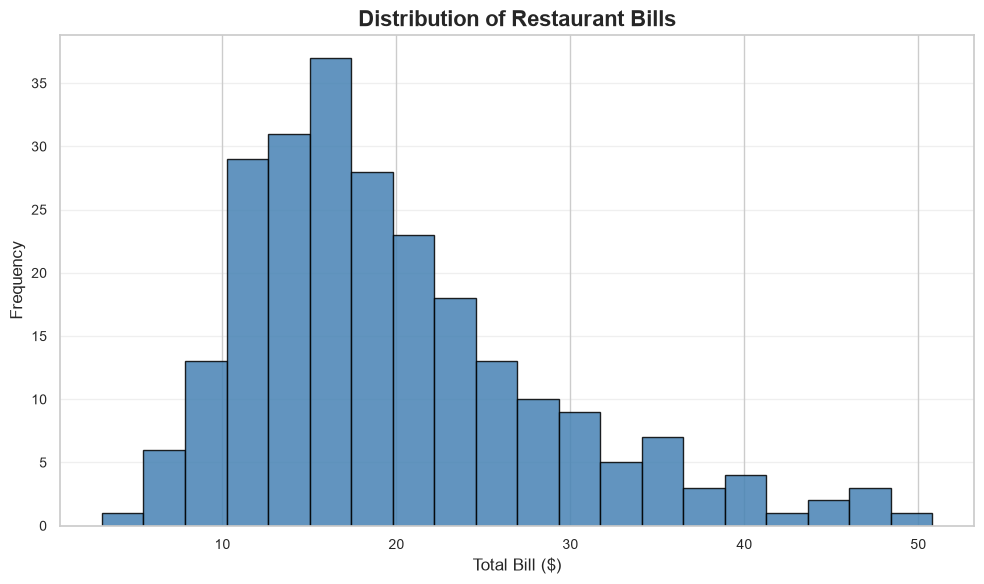

In [4]:
# Histogram using Matplotlib

plt.figure(figsize=(10, 6))

plt.hist(
    tips["total_bill"],
    bins=20,
    color="steelblue",
    edgecolor="black",
    alpha=0.85
)

plt.title("Distribution of Restaurant Bills", fontsize=16, fontweight="bold")
plt.xlabel("Total Bill ($)", fontsize=12)
plt.ylabel("Frequency", fontsize=12)

plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

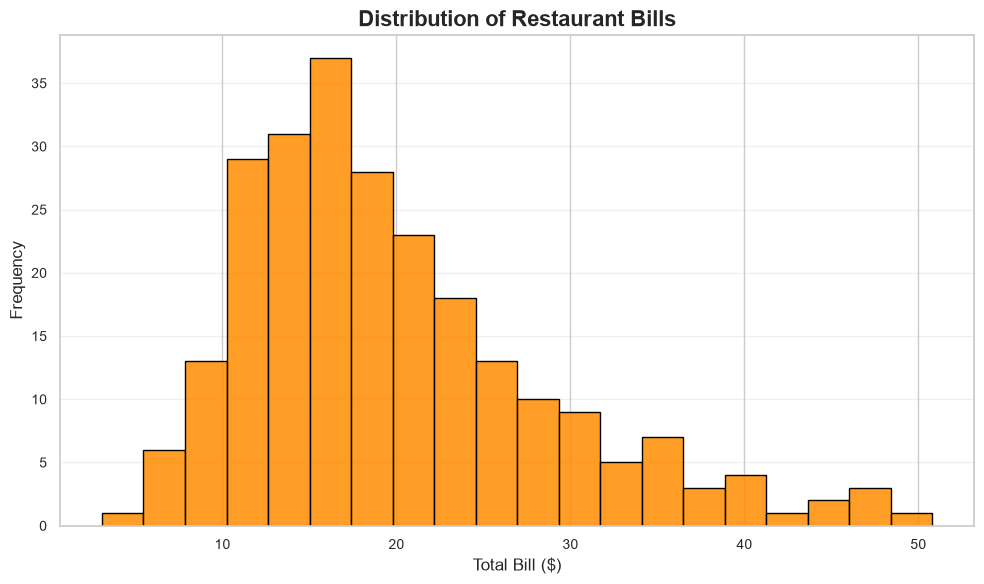

In [5]:
# Histogram using Seaborn

plt.figure(figsize=(10, 6))

sns.histplot(
    data=tips,
    x="total_bill",
    bins=20,
    color="darkorange",
    edgecolor="black",
    alpha=0.85
)

plt.title("Distribution of Restaurant Bills", fontsize=16, fontweight="bold")
plt.xlabel("Total Bill ($)", fontsize=12)
plt.ylabel("Frequency", fontsize=12)

plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Bar charts using Matplotlib and Seaborn, where you'll learn an important difference between plotting raw values and category averages.

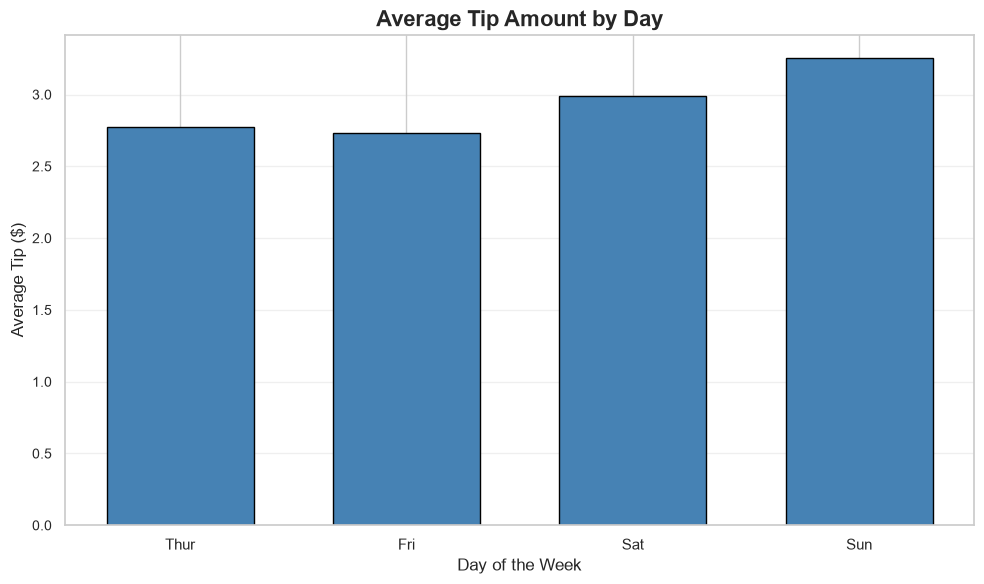

In [6]:
# Calculate average tip for each day
avg_tip = tips.groupby("day", observed=False)["tip"].mean()

plt.figure(figsize=(10, 6))

plt.bar(
    avg_tip.index,
    avg_tip.values,
    color="steelblue",
    edgecolor="black",
    width=0.65
)

plt.title("Average Tip Amount by Day", fontsize=16, fontweight="bold")
plt.xlabel("Day of the Week", fontsize=12)
plt.ylabel("Average Tip ($)", fontsize=12)

plt.xticks(fontsize=11)
plt.yticks(fontsize=10)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

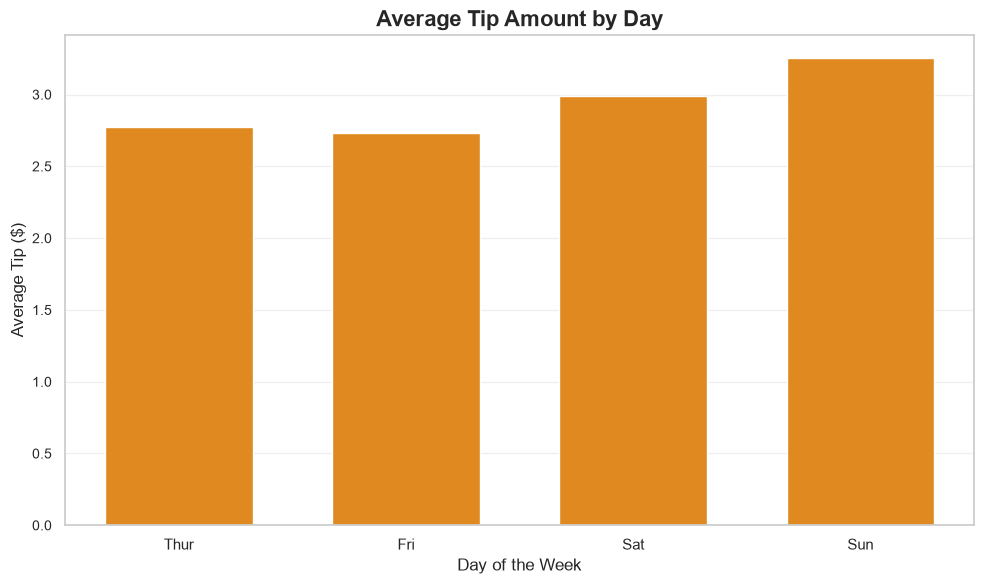

In [7]:
# Bar chart using Seaborn

plt.figure(figsize=(10, 6))

sns.barplot(
    data=tips,
    x="day",
    y="tip",
    color="darkorange",
    errorbar=None,
    width=0.65
)

plt.title("Average Tip Amount by Day", fontsize=16, fontweight="bold")
plt.xlabel("Day of the Week", fontsize=12)
plt.ylabel("Average Tip ($)", fontsize=12)

plt.xticks(fontsize=11)
plt.yticks(fontsize=10)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Box Plot — Total Bill by Day.

A box plot helps you compare distributions, including the median, spread, and potential outliers.

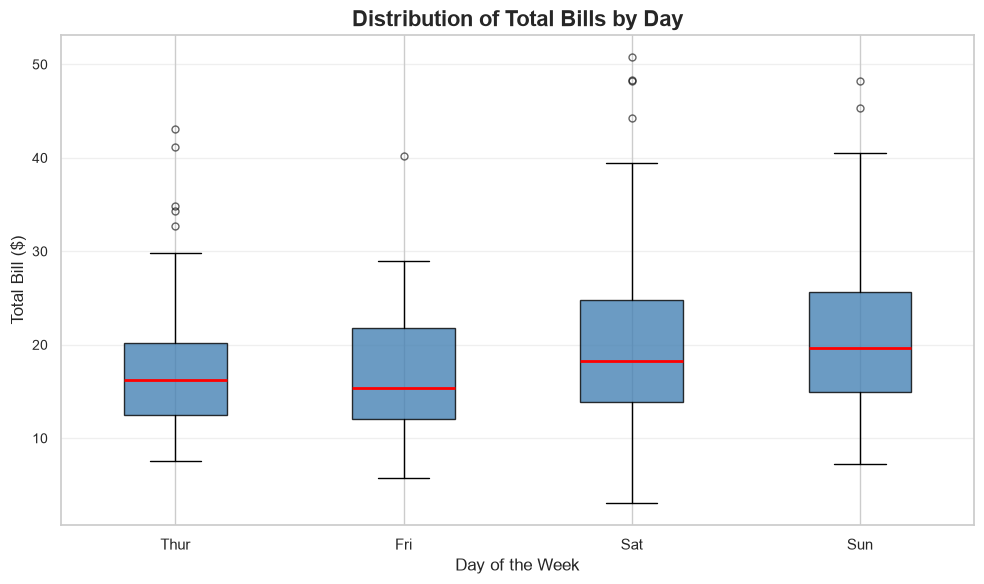

In [8]:
# Box plot using Matplotlib

days = ["Thur", "Fri", "Sat", "Sun"]

bill_data = [
    tips.loc[tips["day"] == day, "total_bill"]
    for day in days
]

plt.figure(figsize=(10, 6))

plt.boxplot(
    bill_data,
    tick_labels=days,
    patch_artist=True,
    boxprops=dict(facecolor="steelblue", alpha=0.8),
    medianprops=dict(color="red", linewidth=2),
    whiskerprops=dict(color="black"),
    capprops=dict(color="black"),
    flierprops=dict(marker="o", markersize=5, alpha=0.6)
)

plt.title("Distribution of Total Bills by Day", fontsize=16, fontweight="bold")
plt.xlabel("Day of the Week", fontsize=12)
plt.ylabel("Total Bill ($)", fontsize=12)

plt.xticks(fontsize=11)
plt.yticks(fontsize=10)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

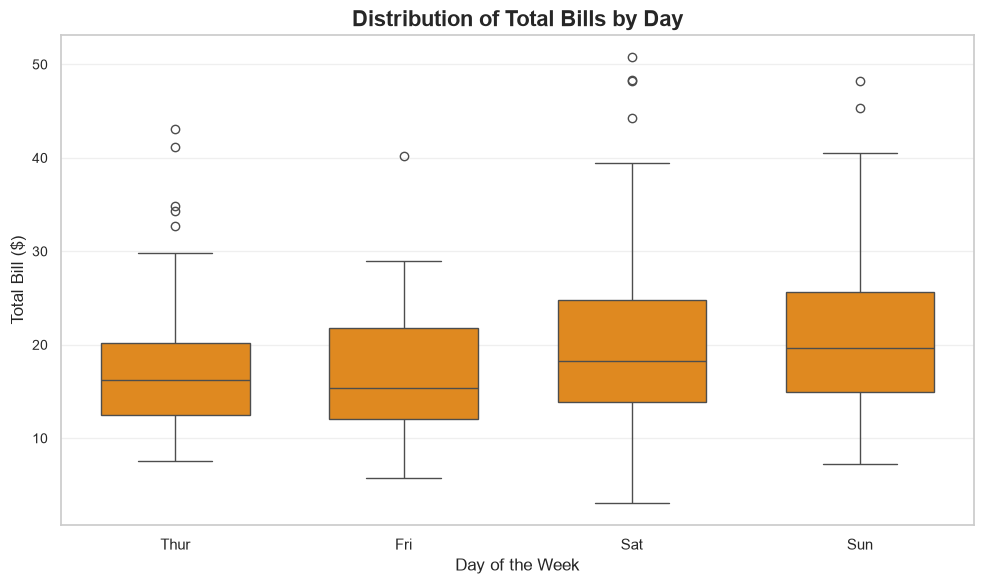

In [9]:
# Box plot using Seaborn

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=tips,
    x="day",
    y="total_bill",
    order=days,
    color="darkorange",
    width=0.65
)

plt.title("Distribution of Total Bills by Day", fontsize=16, fontweight="bold")
plt.xlabel("Day of the Week", fontsize=12)
plt.ylabel("Total Bill ($)", fontsize=12)

plt.xticks(fontsize=11)
plt.yticks(fontsize=10)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Matplotlib scatter plot

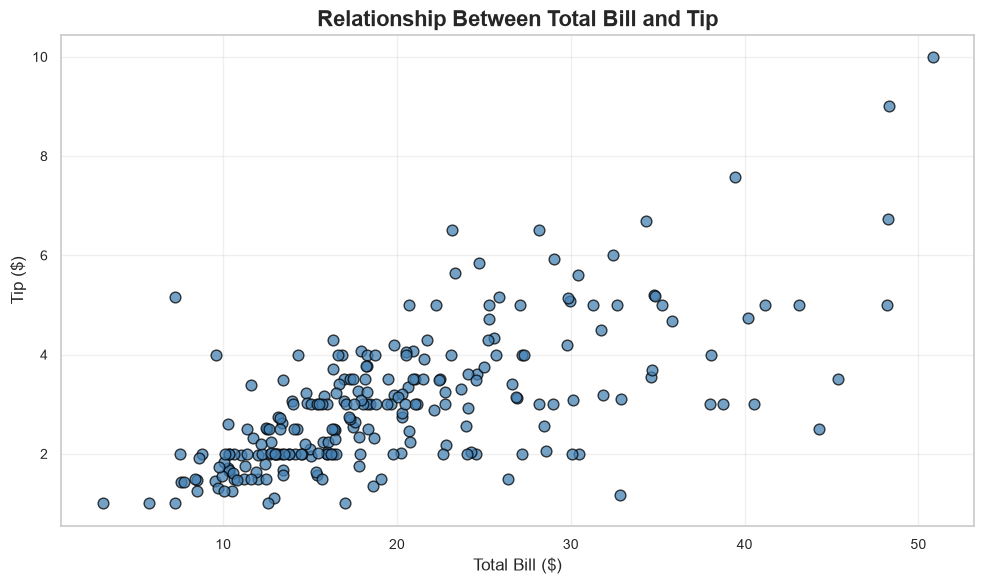

In [10]:
# Scatter plot using Matplotlib

plt.figure(figsize=(10, 6))

plt.scatter(
    tips["total_bill"],
    tips["tip"],
    color="steelblue",
    alpha=0.75,
    edgecolors="black",
    s=60
)

plt.title("Relationship Between Total Bill and Tip",
          fontsize=16, fontweight="bold")
plt.xlabel("Total Bill ($)", fontsize=12)
plt.ylabel("Tip ($)", fontsize=12)

plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Seaborn scatter plot

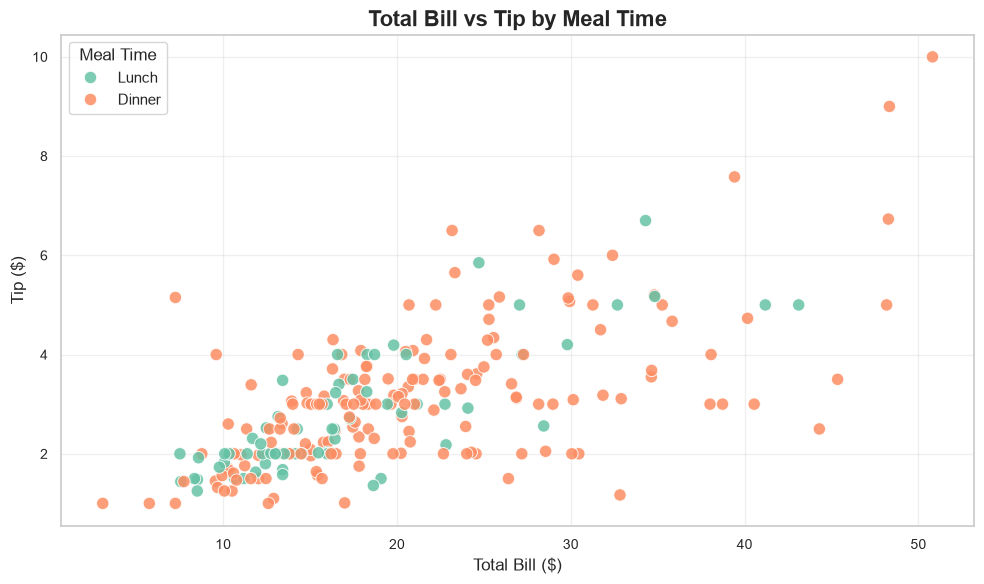

In [11]:
# Scatter plot using Seaborn

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=tips,
    x="total_bill",
    y="tip",
    hue="time",
    palette="Set2",
    s=80,
    alpha=0.85
)

plt.title("Total Bill vs Tip by Meal Time",
          fontsize=16, fontweight="bold")
plt.xlabel("Total Bill ($)", fontsize=12)
plt.ylabel("Tip ($)", fontsize=12)

plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.legend(title="Meal Time")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [12]:
# Select numerical columns and calculate correlations

numerical_data = tips.select_dtypes(include="number")

correlation_matrix = numerical_data.corr()

correlation_matrix

,total_bill,tip,size
total_bill,1.000000,0.675734,0.598315
tip,0.675734,1.000000,0.489299
size,0.598315,0.489299,1.000000


Correlation heatmap

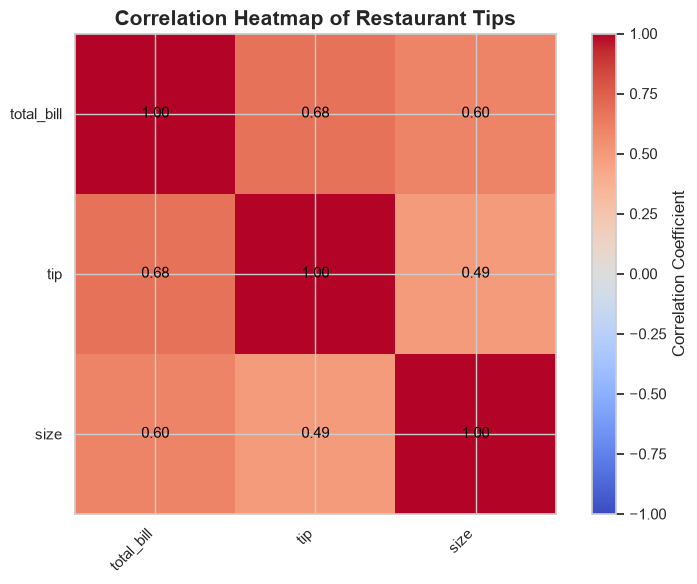

In [13]:
# Heatmap using Matplotlib

plt.figure(figsize=(8, 6))

plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Correlation Coefficient")

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

# Add correlation values to the cells
for i in range(len(correlation_matrix.columns)):
    for j in range(len(correlation_matrix.columns)):
        plt.text(
            j,
            i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            color="black",
            fontsize=11
        )

plt.title("Correlation Heatmap of Restaurant Tips",
          fontsize=15, fontweight="bold")

plt.tight_layout()
plt.show()

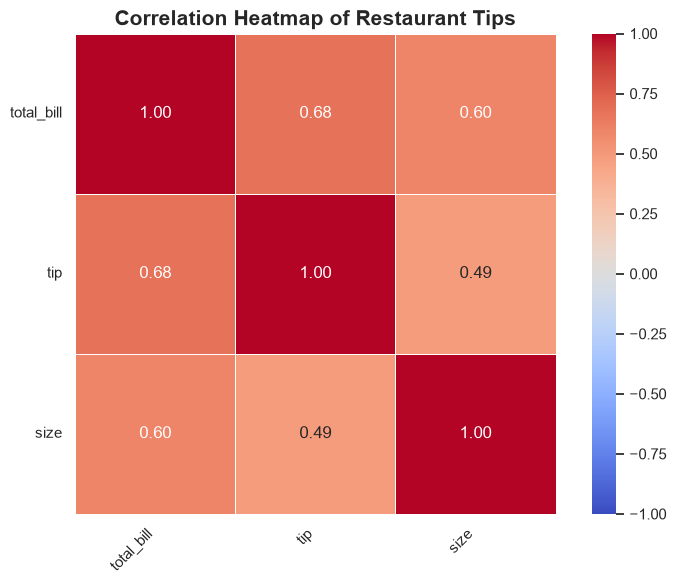

In [14]:
# Heatmap using Seaborn

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True
)

plt.title("Correlation Heatmap of Restaurant Tips",
          fontsize=15, fontweight="bold")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

Save the chart

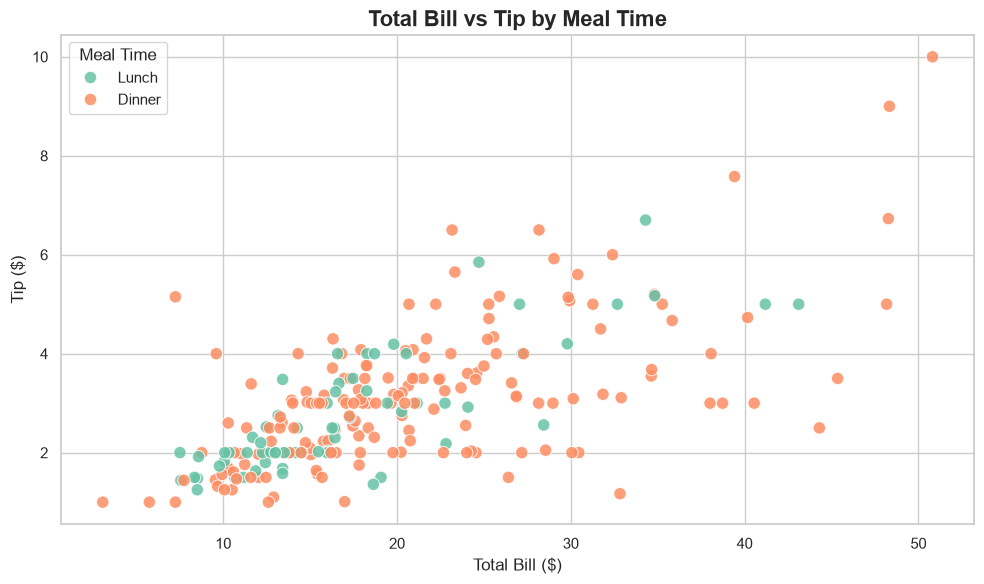

Chart saved to: C:\images\tips_scatter_plot.png


In [16]:
from pathlib import Path

# Create an images folder in the current project directory
output_dir = Path(
    r"C:\Users\MARTIN'S\Documents\matplotlib-seaborn-data-visualization\images"
)
output_dir.mkdir(parents=True, exist_ok=True)

# Recreate the chart before saving it
fig, ax = plt.subplots(figsize=(10, 6))

sns.scatterplot(
    data=tips,
    x="total_bill",
    y="tip",
    hue="time",
    palette="Set2",
    s=80,
    alpha=0.85,
    ax=ax
)

ax.set_title(
    "Total Bill vs Tip by Meal Time",
    fontsize=16,
    fontweight="bold"
)
ax.set_xlabel("Total Bill ($)", fontsize=12)
ax.set_ylabel("Tip ($)", fontsize=12)
ax.legend(title="Meal Time")

fig.tight_layout()

# Save at high resolution
output_file = output_dir / "tips_scatter_plot.png"
fig.savefig(output_file, dpi=300, bbox_inches="tight")

plt.show()

print(f"Chart saved to: {output_file.resolve()}")